In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [ ]:
#Load the dataset
wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

print('Shape of X:', X.shape)
print('Shape of y:', y.shape)
X.head()

#Exploring the data
print(X.info())
print('\nMissing values:')
print(X.isnull().sum().sum())

X.describe().T

# Data Splitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

# Standardizing the Features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Shape of X: (178, 13)
Shape of y: (178,)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                

In [ ]:
#Applying PCA
pca_full = PCA()
X_train_pca_full = pca_full.fit_transform(X_train_scaled)

explained_variance = pca_full.explained_variance_ratio_

variance_table = pd.DataFrame({
    'Component': range(1, len(explained_variance) + 1),
    'Explained Variance': explained_variance,
    'Cumulative Variance': np.cumsum(explained_variance)
})
variance_table




,Component,Explained Variance,Cumulative Variance
0,1,0.357921,0.357921
1,2,0.192707,0.550628
2,3,0.110198,0.660826
3,4,0.072723,0.733549
4,5,0.067219,0.800768
5,6,0.051319,0.852087
6,7,0.043774,0.895862
7,8,0.025009,0.920870
8,9,0.022794,0.943665
9,10,0.018771,0.962436


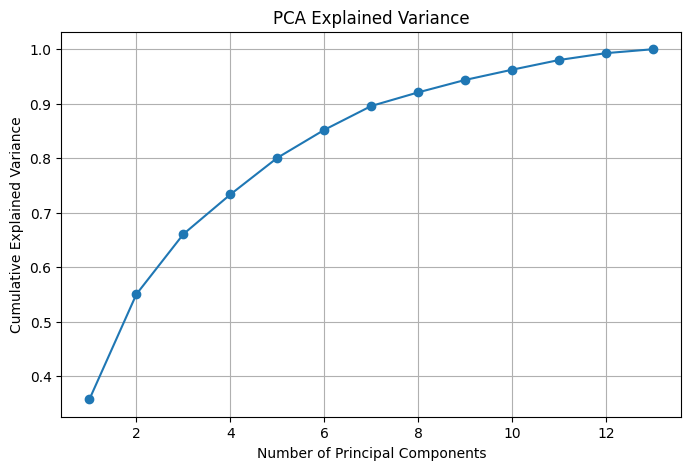

Original number of features: 13
Number of PCA components: 2
Variance explained by 2 components: 0.5506277578733126


In [ ]:
# Visualizing the cummulative explained Variance
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_variance) + 1),
    np.cumsum(explained_variance),
    marker='o'
)
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Explained Variance')
plt.grid(True)
plt.show()

#Reducing features
pca_2 = PCA(n_components=2)

X_train_pca = pca_2.fit_transform(X_train_scaled)
X_test_pca = pca_2.transform(X_test_scaled)

print('Original number of features:', X_train.shape[1])
print('Number of PCA components:', X_train_pca.shape[1])
print('Variance explained by 2 components:', pca_2.explained_variance_ratio_.sum())


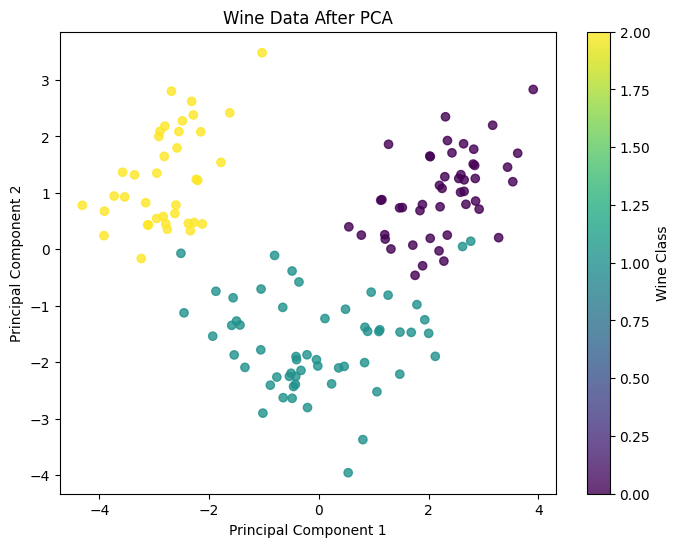

In [ ]:
#Visualization of PCA Representation
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap='viridis',
    alpha=0.8
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Wine Data After PCA')
plt.colorbar(scatter, label='Wine Class')
plt.show()

In [ ]:
#Classification without PCA
model_original = LogisticRegression(max_iter=5000)
model_original.fit(X_train_scaled, y_train)

pred_original = model_original.predict(X_test_scaled)
accuracy_original = accuracy_score(y_test, pred_original)

print('Accuracy without PCA:', accuracy_original)
print('\nClassification report:')
print(classification_report(y_test, pred_original))

#Classification with PCA
model_pca = LogisticRegression(max_iter=5000)
model_pca.fit(X_train_pca, y_train)

pred_pca = model_pca.predict(X_test_pca)
accuracy_pca = accuracy_score(y_test, pred_pca)

print('Accuracy with 2 PCA components:', accuracy_pca)
print('\nClassification report:')
print(classification_report(y_test, pred_pca))


Accuracy without PCA: 0.9722222222222222

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

Accuracy with 2 PCA components: 0.9166666666666666

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92        12
           1       0.87      0.93      0.90        14
           2       1.00      0.90      0.95        10

    accuracy                           0.92        36
   macro avg       0.93      0.92      0.92        36
weighted avg       0.92      0.92      0.92        36



In [ ]:
#Model Comparison
comparison = pd.DataFrame({
    'Model': ['Logistic Regression - Original Features', 'Logistic Regression - 2 PCA Components'],
    'Number of Features': [X_train.shape[1], X_train_pca.shape[1]],
    'Test Accuracy': [accuracy_original, accuracy_pca]
})

comparison


,Model,Number of Features,Test Accuracy
0,Logistic Regression - Original Features,13,0.972222
1,Logistic Regression - 2 PCA Components,2,0.916667


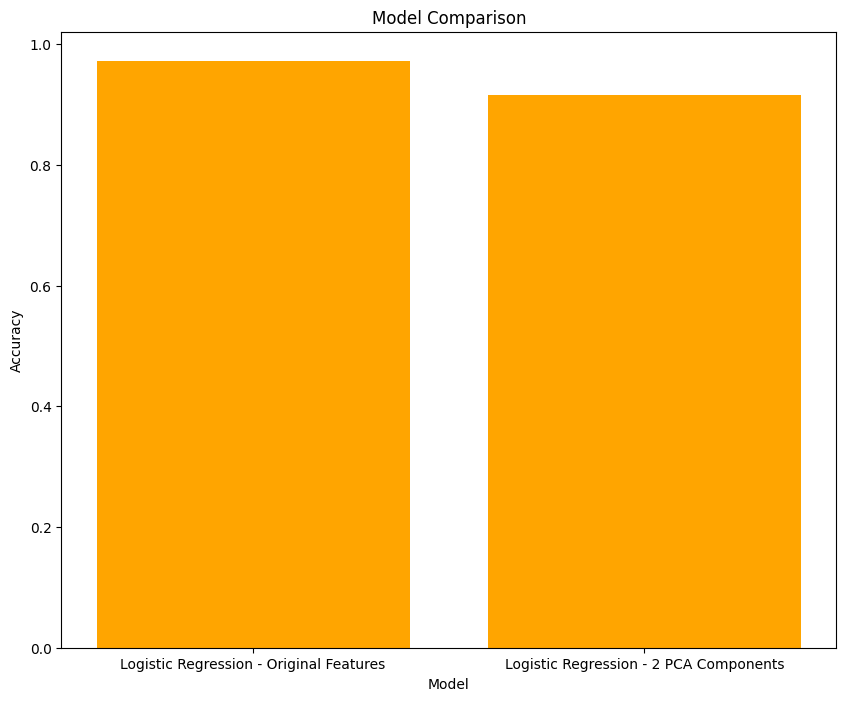

In [22]:
#visualizing the comparison
plt.figure( figsize=(10,8))
plt.bar(comparison["Model"],comparison["Test Accuracy"],color="Orange")
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Model Comparison')
plt.show()